In [1]:
import sys
# sys.path.append('/home/solstud/posada3/')
sys.path.append('/home/tarasenko/prj/posada3/') #last version on my computer
import os

from posada.Handlers import Sentinel_1 as SAR
from posada.Models import Swath
from posada.Readers import SAFE
from posada.Handlers import basesar 


pn = '/nfs1/store/satellite/sentinel-1/'
fn = 'S1A_EW_GRDM_1SDH_20170316T070602_20170316T070702_015714_019DCE_F9D3.zip'
pol = 'hh'
res_m = 500

sarf = SAFE(url=pn+fn, polarisation=pol)
sar = Swath()
sar.load(sarf)
sar.add_handler(SAR)
sar.set_spacing(sar.resolution2spacing(res_m))

s0 = sar.get_values('sigma0')
lat = sar.get_values( 'lat')
lon = sar.get_values( 'lon')


# Nice images from Albert Murtazin
s0_corr = sar.get_values('nice_image')

# Wind values
wind_speed = sar.get_values('wind_speed')

/usr/local/lib/python3.4/dist-packages/pyresample/kd_tree.py:389: UserWarning: Possible more than 40 neighbours within 50000.0 m for some data points
  (neighbours, radius_of_influence))


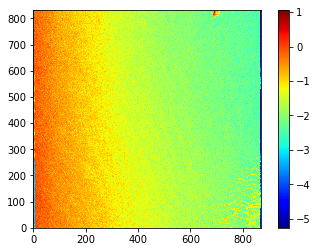

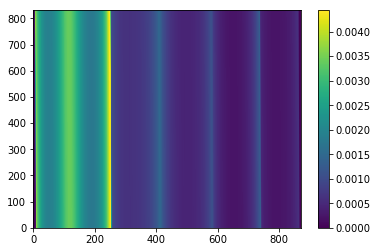

In [2]:
# Trying to get the wind with corrected sigma
# 1) Get sigma - thermal noise
from posada.Handlers.sentinel_1 import change_thermal_noise
import numpy as np
import matplotlib
import matplotlib.pyplot as plt



def get_values_thermalnoise(url, sigma0, inc):
# From  Sentinel_1(BaseSAR)._get_values_nice_image_hh_vv(self, slices=None, **kwargs) in posada/Handlers/sentinel-1.py
        from scipy.interpolate import interp1d
        from posada.Handlers.resources import sentinel_koeffs as sk
        from posada.Handlers.sentinel_1 import change_thermal_noise

        tnoise_new, flatline = change_thermal_noise(sk.tnoise, sk.incvec)
        fnoise_new = interp1d(sk.incvec, tnoise_new,
                              kind='slinear')
        
        sigma0 = np.ma.array(sigma0, mask=np.zeros_like(sigma0))
        sigma0_corr = sigma0 - fnoise_new(inc)

        return tnoise_new, sk.incvec, sigma0_corr, sigma0

inc = sar.get_values('incidence')
tnoise_n, incvec,  sigma0_corr, sigma0 = get_values_thermalnoise(pn+fn, s0, inc)  


plt.pcolormesh(np.log10(sigma0), cmap='jet',)
plt.axis('image')
plt.colorbar()
plt.show()



plt.pcolormesh(sigma0 - sigma0_corr)
plt.colorbar()
plt.show()





/usr/local/lib/python3.4/dist-packages/pyresample/kd_tree.py:389: UserWarning: Possible more than 40 neighbours within 50000.0 m for some data points
  (neighbours, radius_of_influence))


exception


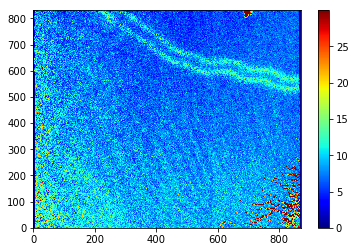

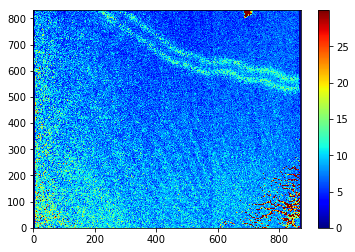

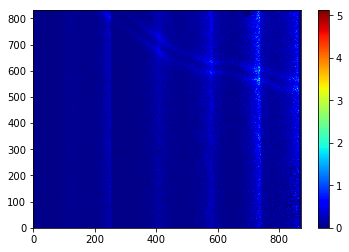

In [4]:
# 2) Recancilate the wind with corrected sigma (won't work on mag's server, cause the )
from cmod.cmod_gpu import rcs2windOpenCl
from posada.Handlers import basesar 

wdir_interim = sar.get_values('wind_dir_era_interim')


# this is part of the function 'compute_wind_speed' in basesar.py


PR = basesar.PR_Mouche(inc, wdir_interim)
try:
    from cmod.cmod_gpu import rcs2windOpenCl
    windSAR = rcs2windOpenCl(sar=sigma0 * PR,
                             windir=wdir_interim,
                             theta=inc)
except Exception:
    from cmod.cmod_vect import rcs2windPar
    windSAR = rcs2windPar(sar=sigma0 * PR, cmdv=5,
                          windir=wdir_interim,
                          theta=inc,
                          nprocs=4)
    
try:
    from cmod.cmod_gpu import rcs2windOpenCl
    windSAR_corr = rcs2windOpenCl(sar=sigma0_corr * PR,
                                  windir=wdir_interim,
                                  theta=inc)
except Exception:
    from cmod.cmod_vect import rcs2windPar
    windSAR_corr = rcs2windPar(sar=sigma0_corr * PR, cmdv=5,
                               windir=wdir_interim,
                               theta=inc,
                               nprocs=4)



plt.pcolormesh(windSAR, cmap='jet')
plt.colorbar()
plt.show()



windSAR_corr_ma = np.ma.masked_where(windSAR_corr<0, windSAR_corr)
plt.pcolormesh(windSAR_corr_ma, cmap='jet')
plt.colorbar()
plt.show()     



plt.pcolormesh(windSAR-windSAR_corr, cmap='jet')
plt.colorbar()
plt.show()   
# windSAR = basesar.compute_wind_speed(sigma0, inc, pol, wdir_interim, nprocs=4)
    
    

In [5]:
sar.get_field_names() 

['lat',
 'sigma0_lut',
 'wind_dir_ncep_gfs',
 'digital_number',
 'elevation',
 'nice_image',
 'mask',
 'roughness',
 'incidence',
 'gamma0_lut',
 'azimuth_time',
 'lon',
 'slant_range_time',
 'wind_dir_era_interim',
 'doppler_centroid',
 'gamma0',
 'complex',
 'wind_dir',
 'sigma0',
 'wind_speed',
 'beta0_lut',
 'beta0']